# 11C. Дообучение детектора: pgd

PGD генерируется на текущих весах. Доля растёт до 25%, ε от 1/255 до 4/255, шагов до 5. Первые 100 optimizer-шагов без атак, затем ramp 400 шагов. Остальные natural-воздействия сохраняются. На PGD-шагах loss = 0,25×clean + 0,75×adversarial; патчи в этом эксперименте не используются.


Старая версия не изменяется: исходный release/, его ZIP и checkpoints только читаются. Все новые веса, конфигурация, код и результаты записываются в отдельный RUN_ID. Ни переупаковки, ни переподписи, ни замены рабочего релиза нет. Final и development для подбора этой ветки не используются.

In [ ]:
import sys, subprocess, importlib.util
from pathlib import Path
sys.dont_write_bytecode = True  # не создавать __pycache__ в старых каталогах
IN_COLAB = 'google.colab' in sys.modules or Path('/content').is_dir()
if IN_COLAB:
    from google.colab import drive
    drive.mount('/content/drive')
    PROJECT = Path('/content/drive/MyDrive/ML6')
else:
    PROJECT = Path('D:/ML6')
packages = {'scipy':'scipy', 'pandas':'pandas', 'cv2':'opencv-python-headless',
            'matplotlib':'matplotlib', 'tqdm':'tqdm', 'cryptography':'cryptography'}
missing = [p for m,p in packages.items() if importlib.util.find_spec(m) is None]
if missing:
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', *missing])
BUNDLE = PROJECT/'notebooks_colab_full'
assert (BUNDLE/'tracking_lab.py').is_file(), BUNDLE
sys.path.insert(0, str(BUNDLE))
import tracking_lab as bootstrap_tl
assert Path(bootstrap_tl.__file__).resolve() == (BUNDLE/'tracking_lab.py').resolve(), 'Перезапустите runtime'
import torch, pandas as pd, numpy as np, matplotlib.pyplot as plt
from IPython.display import display
print('Устройство:', 'cuda' if torch.cuda.is_available() else 'cpu')
print('GPU:', torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'нет')


Mounted at /content/drive
Устройство: cuda
GPU: NVIDIA L4


Служебный код встроен; отдельные .py-файлы загружать не нужно. Определение функций не запускает обучение.

In [ ]:

import copy
import gc
import hashlib
import importlib.util
import json
import math
import os
import random
import shutil
import sys
from pathlib import Path
import time

import numpy as np
import pandas as pd
import torch


def finetune_defaults():
    return dict(seed=20261114, frame_budget=6000, rounds=4, checkpoint_every=500,
        head_lr=2e-5, backbone_lr=5e-6, weight_decay=1e-4, gradient_clip=5.,
        pgd_fraction=.25, adversarial_loss_weight=.75, warmup_steps=100, ramp_steps=400,
        epsilon_start=1/255, epsilon=4/255, alpha=1/255, train_attack_steps=5,
        val_frames_per_video=4, eval_steps=20, eval_restarts=3,
        confirm_steps=40, confirm_restarts=3, clean_ap50_drop=.03,
        minimum_pgd_gain=.005, minimum_gain_over_control=.0025,
        minimum_pgd_examples=128, max_zero_gradient_fraction=.05)


def sha(path):
    h = hashlib.sha256()
    with Path(path).open('rb') as stream:
        for part in iter(lambda: stream.read(4*1024*1024), b''):
            h.update(part)
    return h.hexdigest()


def read_json(path):
    return json.loads(Path(path).read_text(encoding='utf-8-sig'))


def write_json(path, value):
    path = Path(path); path.parent.mkdir(parents=True, exist_ok=True)
    temp = path.with_name(path.name+'.part')
    temp.write_text(json.dumps(value, ensure_ascii=False, indent=2, allow_nan=False), encoding='utf-8')
    os.replace(temp, path)


def safe_destination(root, relative):
    root = Path(root).resolve()
    path = (root/relative).resolve()
    if not path.is_relative_to(root) or path == root:
        raise ValueError('Запись разрешена только внутри новой ветки')
    return path


def copy_once(source, destination):
    source, destination = Path(source), Path(destination)
    expected = sha(source)
    if destination.exists():
        if sha(destination) != expected:
            raise ValueError(f'Новая ветка уже содержит другой файл: {destination}')
        return expected
    destination.parent.mkdir(parents=True, exist_ok=True)
    temp = destination.with_name(destination.name+'.part')
    shutil.copyfile(source, temp)
    if sha(temp) != expected:
        raise IOError('Ошибка копирования в новую ветку')
    os.replace(temp, destination)
    return expected


def coverage_order(records, total, seed):
    """Interleave videos, use all frames before any frame can repeat."""
    rng, result, cycles = random.Random(seed), [], 0
    while len(result) < total:
        groups = {}
        for index, record in enumerate(records):
            groups.setdefault(record['video'], []).append(index)
        for queue in groups.values():
            rng.shuffle(queue)
        while groups and len(result) < total:
            videos = sorted(groups); rng.shuffle(videos)
            for video in videos:
                result.append(groups[video].pop())
                if not groups[video]:
                    del groups[video]
                if len(result) == total:
                    break
        cycles += 1
    return result


def finetune_schedule(recipe, step, arm):
    if arm not in ('control', 'pgd'):
        raise ValueError(arm)
    strength = min(1., max(0., (step-recipe['warmup_steps'])/max(1, recipe['ramp_steps'])))
    return dict(strength=strength, probability=recipe['pgd_fraction']*strength if arm == 'pgd' else 0.,
        epsilon=recipe['epsilon_start']+(recipe['epsilon']-recipe['epsilon_start'])*strength,
        steps=max(1, math.ceil(recipe['train_attack_steps']*strength)))


def training_mode(recipe, step, arm):
    u = random.Random(recipe['seed']+step*17+3).random()
    # Identical natural corruptions in both arms. PGD replaces only clean slots.
    cumulative = 0.
    for kind, probability in [('photo', .15), ('jpeg', .10), ('noise', .05), ('blur', .05), ('geometry', .05), ('occlusion', .05)]:
        cumulative += probability
        if u < cumulative:
            return kind
    return 'pgd' if u >= 1-finetune_schedule(recipe, step, arm)['probability'] else 'clean'


def checkpoint_roles(rows, baseline, recipe, arm):
    if not rows:
        return {}
    floor = baseline['clean_AP50']-recipe['clean_ap50_drop']
    clean = max(rows, key=lambda r: (r['clean_AP50'], -r['round']))
    feasible = [r for r in rows if r['clean_AP50'] >= floor and
        r['zero_gradient_fraction'] <= recipe['max_zero_gradient_fraction'] and
        (arm == 'control' or (r['completed_steps'] >= recipe['warmup_steps']+recipe['ramp_steps']
                              and r['pgd_examples'] >= recipe['minimum_pgd_examples']))]
    roles = {'best_clean': clean}
    if feasible:
        roles['best_robust'] = max(feasible, key=lambda r: (r['pgd_AP50'], r['clean_AP50'], -r['round']))
    return roles


class FineTuneBranch:
    def __init__(self, project, source_run, new_run, recipe, bootstrap, expected_public_key=None):
        self.project = Path(project).resolve()
        if Path(source_run).name != source_run or Path(new_run).name != new_run or new_run in ('.', '..', source_run):
            raise ValueError('Нужен отдельный безопасный NEW_RUN_ID')
        self.source = (self.project/'runs'/source_run).resolve()
        self.root = safe_destination(self.project/'runs', new_run)
        if self.root.is_relative_to(self.source) or self.source.is_relative_to(self.root):
            raise ValueError('Новая ветка должна быть отдельной от исходной')
        self.recipe = copy.deepcopy(recipe)
        if (not 0 < recipe['pgd_fraction'] <= .55 or not 0 < recipe['adversarial_loss_weight'] < 1
                or recipe['rounds'] < 1 or recipe['checkpoint_every'] < 1
                or not 0 < recipe['epsilon'] <= 1 or recipe['train_attack_steps'] < 1):
            raise ValueError('Некорректная конфигурация пилота')
        self.release = self.source/'release'
        anchor = self.source/'artifacts/release_trust_anchor.json'
        expected = expected_public_key or (read_json(anchor)['public_key'] if anchor.exists() else None)
        self.status = bootstrap.verify_release(self.release, expected)
        self.manifest = read_json(self.release/'release.json')
        files = self.manifest['payload']['files']
        if self.manifest['payload']['variant'] != 'natural':
            raise ValueError('Ожидался natural-релиз')
        required = ['tracking_lab.py', 'legacy_core.py', 'controlled_data.py', 'dataset_lifecycle.py',
                    'detector.pt', 'reid.pt', 'tracker.json', 'association.json', 'config.json']
        if not set(required) <= set(files):
            raise ValueError('Релиз неполон')
        protected = {str(path.relative_to(self.project)): sha(path)
                     for path in self.release.rglob('*') if path.is_file()}
        for path in [anchor, self.source/f'reports/{source_run}_repaired_release.zip',
                     self.source/'configs/project_config.json',
                     self.source/'data/manifests/frames.json', self.source/'data/manifests/frames_meta.json']:
            if path.exists():
                protected[str(path.relative_to(self.project))] = sha(path)
        self.protected = protected
        self.root.mkdir(parents=True, exist_ok=True)
        self.path('code').mkdir(parents=True, exist_ok=True)
        engine_hash = hashlib.sha256(FINETUNE_ENGINE_SOURCE.encode('utf-8')).hexdigest()
        specification = dict(source_run=source_run, new_run=new_run, recipe=recipe,
            release_id=self.status['release_id'], protected=protected, engine_sha256=engine_hash)
        spec_file = self.path('configs/branch_specification.json')
        if spec_file.exists() and read_json(spec_file) != specification:
            raise ValueError('Рецепт, код или исходные файлы изменились. Используйте другой NEW_RUN_ID.')
        write_json(spec_file, specification)
        for name in ['tracking_lab.py', 'legacy_core.py', 'controlled_data.py', 'dataset_lifecycle.py']:
            copy_once(self.release/name, self.path('code/'+name))
        engine_file = self.path('code/finetune_engine.py')
        if engine_file.exists() and sha(engine_file) != engine_hash:
            raise ValueError('Код новой ветки изменён')
        engine_file.write_text(FINETUNE_ENGINE_SOURCE, encoding='utf-8', newline='\n')
        # Disable bytecode writes even while importing source dependencies.
        sys.dont_write_bytecode = True
        name = 'tracking_lab_advft_'+hashlib.sha256(str(self.root).encode()).hexdigest()[:16]
        module_spec = importlib.util.spec_from_file_location(name, self.path('code/tracking_lab.py'))
        self.f = importlib.util.module_from_spec(module_spec)
        sys.modules[name] = self.f
        module_spec.loader.exec_module(self.f)
        for module in [self.f.base, self.f.cd, self.f.lifecycle]:
            if sha(module.__file__) != files[Path(module.__file__).name]:
                raise ValueError('Загружена другая версия вспомогательных модулей. Перезапустите runtime.')
        cfg = read_json(self.release/'config.json')
        cfg.update(run_name=new_run, seed=recipe['seed'], retire_train_mp4=False, reserve_remove_count=0,
                   detector_lr=recipe['head_lr'], detector_backbone_lr=recipe['backbone_lr'],
                   detector_epochs=recipe['rounds'], checkpoint_every=recipe['checkpoint_every'],
                   train_attack_steps=recipe['train_attack_steps'], eval_attack_steps=recipe['eval_steps'],
                   eval_restarts=recipe['eval_restarts'], epsilon=recipe['epsilon'], attack_step=recipe['alpha'],
                   training_driver='isolated_detector_finetune', adv_finetune_recipe=recipe)
        cfg['tracker'] = read_json(self.release/'tracker.json')
        cfg['augment']['mixture'].update(clean=.55-recipe['pgd_fraction'], pgd=recipe['pgd_fraction'])
        cfg['augment']['optimized_patch_probability'] = 0.
        cfg['augment']['combinations'] = []; cfg['augment']['combination_probability'] = 0.
        self.f.cd.validate_config(cfg['augment'])
        config_path = self.path('configs/project_config.json')
        if config_path.exists() and read_json(config_path) != cfg:
            raise ValueError('Конфигурация новой ветки уже зафиксирована')
        write_json(config_path, cfg)
        # Avoid Lab.__init__: its directory creation can follow a shared archive reference.
        self.lab = object.__new__(self.f.Lab)
        self.lab.root, self.lab.project, self.lab.cfg = self.root, self.project, cfg
        self.lab.device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
        for directory in ['configs', 'data/manifests', 'checkpoints', 'artifacts', 'reports']:
            self.path(directory).mkdir(parents=True, exist_ok=True)
        source_records = read_json(self.source/'data/manifests/frames.json')
        metadata = read_json(self.source/'data/manifests/frames_meta.json')
        if self.f.digest(source_records) != metadata['sha256'] or len(metadata['clean_frame_sha256']) != len(source_records):
            raise ValueError('Исходный manifest кадров не прошёл проверку')
        archive_root = self.source/'data/frame_archives'
        old_reference = self.source/'configs/prepared_data_source.json'
        if old_reference.exists():
            reference = read_json(old_reference)
            if not reference.get('complete'):
                raise ValueError('Исходная подготовка кадров не завершена')
            archive_root = Path(reference['archive_root'])
        archive_root = archive_root.resolve()
        if not archive_root.is_relative_to(self.project/'runs') or archive_root.name != 'frame_archives' or archive_root.parent.name != 'data':
            raise ValueError('Недопустимый источник архивов')
        adoption = self.path('configs/prepared_data_source.json')
        write_json(adoption, dict(source_run=source_run, archive_root=str(archive_root),
                                  frames_sha256=metadata['sha256'], complete=False))
        for path in (self.source/'data/manifests').iterdir():
            if path.is_file() and path.suffix in ('.json', '.csv'):
                copy_once(path, self.path('data/manifests/'+path.name))
        write_json(adoption, dict(source_run=source_run, archive_root=str(archive_root),
                                  frames_sha256=metadata['sha256'], complete=True))
        for name, target in [('detector.pt', 'checkpoints/initial/detector.pt'),
                             ('reid.pt', 'checkpoints/fixed/reid.pt'), ('tracker.json', 'configs/fixed_tracker.json')]:
            copy_once(self.release/name, self.path(target))
        self.train, self.val = self.lab.records('train'), self.f.validation_subset(self.lab.records('val'), recipe['val_frames_per_video'])
        if not self.train or not self.val or any(r['split'] != 'train' for r in self.train) or any(r['split'] != 'val' for r in self.val):
            raise ValueError('Нужны train и validation без смешивания')
        self.total_steps = len(self.train) if recipe['frame_budget'] is None else int(recipe['frame_budget'])
        if self.total_steps < recipe['rounds'] or self.total_steps <= recipe['warmup_steps']+recipe['ramp_steps']:
            raise ValueError('Пилот слишком короткий для расписания атак')
        self.boundaries = [math.ceil(self.total_steps*i/recipe['rounds']) for i in range(1, recipe['rounds']+1)]
        self.order = coverage_order(self.train, self.total_steps, recipe['seed'])
        write_json(self.path('data/detector_order.json'), self.order)
        self.contract = self.f.digest(dict(specification=specification, context=self.lab.context(),
            train=self.train, validation=self.val, pixels=self.lab.input_contract(self.train+self.val),
            initial=sha(self.path('checkpoints/initial/detector.pt')), fixed_reid=sha(self.path('checkpoints/fixed/reid.pt')),
            tracker=read_json(self.path('configs/fixed_tracker.json')), order=self.order))
        write_json(self.path('configs/training_contract.json'), dict(contract=self.contract, total_steps=self.total_steps,
            unique_frames=len(set(self.order)), train_videos=len({r['video'] for r in self.train}), validation_frames=len(self.val)))
        torch.hub.set_dir(str(self.path('pretrained_cache')))
        self.f.seed_all(recipe['seed'])
        self.guard()

    def path(self, relative):
        return safe_destination(self.root, relative)

    def guard(self):
        for relative, expected in self.protected.items():
            path = self.project/relative
            if not path.is_file() or sha(path) != expected:
                raise ValueError(f'Изменился защищённый исходный файл: {path}')
        current = {str(path.relative_to(self.project)) for path in self.release.rglob('*') if path.is_file()}
        original = {p for p in self.protected if (self.project/p).is_relative_to(self.release)}
        if current != original:
            raise ValueError('Изменился состав файлов исходного релиза')
        for relative, name in [('checkpoints/initial/detector.pt', 'detector.pt'),
                               ('checkpoints/fixed/reid.pt', 'reid.pt'), ('configs/fixed_tracker.json', 'tracker.json')]:
            if sha(self.path(relative)) != self.manifest['payload']['files'][name]:
                raise ValueError(f'Изменился исходный/фиксированный компонент новой ветки: {relative}')
        return dict(source_release_unchanged=True, protected_files=len(self.protected), new_run=str(self.root))

    def cache(self, local_root, train=False):
        if Path(local_root).resolve().is_relative_to(self.source):
            raise ValueError('Локальный кэш нельзя записывать в исходный запуск')
        self.f.cache_frames(self.lab, local_root, splits=('train', 'val') if train else ('val',))

    def baseline(self):
        if sha(self.path('checkpoints/initial/detector.pt')) != self.manifest['payload']['files']['detector.pt']:
            raise ValueError('Исходные веса новой ветки не совпадают с релизом')
        return dict(path='checkpoints/initial/detector.pt', round=0, completed_steps=0,
                    pgd_examples=0, weights_sha256=sha(self.path('checkpoints/initial/detector.pt')))

    def load_detector(self, reference):
        path = self.path(reference['path'])
        if sha(path) != reference['weights_sha256']:
            raise ValueError('Изменился checkpoint кандидата')
        model = self.f.build_detector(self.lab, pretrained=False)
        model.load_state_dict(torch.load(path, map_location=self.lab.device, weights_only=True))
        return model

    def validate(self, reference, model=None, steps=None, restarts=None):
        f, recipe = self.f, self.recipe
        steps = recipe['eval_steps'] if steps is None else steps
        restarts = recipe['eval_restarts'] if restarts is None else restarts
        if sha(self.path(reference['path'])) != reference['weights_sha256']:
            raise ValueError('Checkpoint изменился перед validation')
        key = f.digest(dict(contract=self.contract, weights=reference['weights_sha256'], steps=steps, restarts=restarts))
        out = self.path('artifacts/validation/'+key); out.mkdir(parents=True, exist_ok=True)
        completion = out/'complete.json'
        if completion.exists():
            proof = read_json(completion)
            if proof['contract'] == key and sha(out/'metrics.csv') == proof['sha256']:
                return pd.read_csv(out/'metrics.csv')
        owned = model is None
        model = self.load_detector(reference) if owned else model
        old_mode, state = model.training, f.rng_state()
        results = []
        try:
            model.eval()
            for scenario in ('clean', 'pgd'):
                predictions, diagnostics = [], []
                for i, record in enumerate(f.tqdm(self.val, desc=f'Validation {scenario}: {reference["path"]}')):
                    frame_key = f.digest(dict(contract=key, record=record, scenario=scenario))
                    path = out/scenario/f'{i:05d}.json'
                    if path.exists():
                        item = read_json(path)
                        if item['contract'] != frame_key:
                            raise ValueError('Несовместимый validation-кэш')
                    else:
                        f.seed_all(recipe['seed']+1000000+i)
                        x = f.frame_tensor(self.lab, record).to(self.lab.device)
                        info = {}
                        if scenario == 'pgd':
                            target = {k: v.to(self.lab.device) for k, v in f.target_of(record).items()}
                            x, info = f.pgd_detector(model, x, target, recipe['epsilon'], steps, recipe['alpha'], restarts=restarts)
                            if info['linf'] > recipe['epsilon']+1e-6:
                                raise ValueError('Validation PGD вышел за epsilon')
                        prediction = f.detect(model, x, self.lab.cfg['ap_score_threshold'])
                        item = dict(contract=frame_key, frame_idx=record['frame_idx'],
                            detections=prediction['boxes'].tolist(), detection_scores=prediction['scores'].tolist(), attack=info)
                        write_json(path, item)
                    predictions.append(item)
                    if scenario == 'pgd':
                        diagnostics.append(item['attack'])
                totals = np.zeros(3, dtype=int)
                for record, prediction in zip(self.val, predictions):
                    keep = np.asarray(prediction['detection_scores']) >= self.lab.cfg['score_threshold']
                    boxes = np.asarray(prediction['detections']).reshape(-1, 4)[keep]
                    boxes, _ = f.filter_ignored(record, boxes, np.ones(len(boxes)))
                    totals += f.base.detection_counts([o['bbox'] for o in record['objects']], boxes)
                tp, fp, fn = map(int, totals)
                results.append(dict(scenario=scenario, AP50=f.base.detection_ap50(self.val, predictions),
                    precision=tp/max(1, tp+fp), recall=tp/max(1, tp+fn), frames=len(self.val),
                    zero_gradient_fraction=float(np.mean([d['gradient_mean_abs'] == 0 for d in diagnostics])) if diagnostics else 0.,
                    linf_max=max([d['linf'] for d in diagnostics] or [0.])))
            table = pd.DataFrame(results)
            if not np.isfinite(table[['AP50', 'precision', 'recall']].to_numpy()).all():
                raise ValueError('Validation содержит нечисловые значения')
            table.to_csv(out/'metrics.csv', index=False)
            write_json(completion, dict(contract=key, sha256=sha(out/'metrics.csv')))
            return table
        finally:
            model.train(old_mode); f.freeze_bn(model)
            f.restore_rng(state)
            if owned:
                del model; gc.collect(); torch.cuda.empty_cache()

    def baseline_validation(self):
        self.guard()
        reference = self.baseline()
        table = self.validate(reference)
        row = self.validation_row(reference, table)
        write_json(self.path('artifacts/baseline.json'), dict(row, contract=self.contract))
        display(table)
        print('Допустимый минимум clean AP50:', row['clean_AP50']-self.recipe['clean_ap50_drop'])
        self.guard()
        return table

    def read_baseline(self):
        baseline = read_json(self.path('artifacts/baseline.json'))
        if baseline.get('contract') != self.contract or baseline['weights_sha256'] != self.baseline()['weights_sha256']:
            raise ValueError('Не совпала исходная validation-оценка; сначала выполните 11A')
        return baseline

    def validation_row(self, reference, table):
        clean, pgd = [table[table.scenario == s].iloc[0] for s in ('clean', 'pgd')]
        return dict(reference, clean_AP50=float(clean.AP50), pgd_AP50=float(pgd.AP50),
                    clean_recall=float(clean.recall), pgd_recall=float(pgd.recall),
                    zero_gradient_fraction=float(pgd.zero_gradient_fraction))

    def save_last(self, arm, model, optimizer, scheduler, completed, history):
        pointer_path = self.path(f'checkpoints/{arm}/last.json')
        previous = read_json(pointer_path) if pointer_path.exists() else None
        slot = 'resume_b.pt' if previous and previous['slot'] == 'resume_a.pt' else 'resume_a.pt'
        path = self.path(f'checkpoints/{arm}/{slot}')
        # Never overwrite the currently committed slot. Commit the pointer only
        # after the new checkpoint and checksum are both fully written.
        self.f.atomic_torch_save(path, dict(
            contract=self.contract, arm=arm, model=model.state_dict(), optimizer=optimizer.state_dict(),
            scheduler=scheduler.state_dict(), completed_steps=completed, history=history,
            rng=self.f.rng_state(), complete=completed == self.total_steps))
        write_json(pointer_path, dict(contract=self.contract, arm=arm, slot=slot,
            path=str(path.relative_to(self.root)), sha256=read_json(path.with_suffix('.sha256.json'))['sha256'],
            completed_steps=completed))
        pd.DataFrame(history).to_csv(self.path(f'checkpoints/{arm}/history.csv'), index=False)

    def resume_pointer(self, arm):
        pointer = read_json(self.path(f'checkpoints/{arm}/last.json'))
        if pointer['contract'] != self.contract or pointer['arm'] != arm:
            raise ValueError('Не совпал контракт состояния продолжения')
        path = self.path(pointer['path'])
        if pointer['slot'] not in ('resume_a.pt', 'resume_b.pt') or path.name != pointer['slot']:
            raise ValueError('Некорректный слот продолжения')
        if sha(path) != pointer['sha256'] or read_json(path.with_suffix('.sha256.json'))['sha256'] != pointer['sha256']:
            raise ValueError('Повреждён зафиксированный checkpoint продолжения')
        return pointer

    def load_last(self, arm):
        pointer = self.resume_pointer(arm)
        # Own local optimizer/RNG state; integrity checked before pickle loading.
        saved = torch.load(self.path(pointer['path']), map_location='cpu', weights_only=False)
        if (saved['contract'] != self.contract or saved['arm'] != arm
                or saved['completed_steps'] != pointer['completed_steps']):
            raise ValueError('Checkpoint продолжения не соответствует указателю')
        return saved

    def save_round(self, arm, round_index, completed, model, history):
        path = self.path(f'checkpoints/{arm}/round_{round_index:03d}.pt')
        if path.exists():
            saved = torch.load(path, map_location='cpu', weights_only=True)
            current = model.state_dict()
            if set(saved) != set(current) or any(not torch.equal(saved[k], current[k].detach().cpu()) for k in saved):
                raise ValueError('Checkpoint раунда не совпадает с возобновлённым состоянием')
        else:
            self.f.atomic_torch_save(path, {k: v.detach().cpu() for k, v in model.state_dict().items()})
        return dict(path=str(path.relative_to(self.root)), round=round_index, completed_steps=completed,
                    pgd_examples=sum(r['mode'] == 'pgd' for r in history), weights_sha256=sha(path))

    def train_arm(self, arm):
        if arm not in ('control', 'pgd'):
            raise ValueError(arm)
        self.guard()
        baseline = self.read_baseline()
        f, recipe = self.f, self.recipe
        f.seed_all(recipe['seed'])
        model = self.load_detector(self.baseline())
        backbone, head = [], []
        for name, parameter in model.named_parameters():
            if parameter.requires_grad:
                (backbone if name.startswith('backbone') else head).append(parameter)
        optimizer = torch.optim.AdamW([dict(params=backbone, lr=recipe['backbone_lr']),
            dict(params=head, lr=recipe['head_lr'])], weight_decay=recipe['weight_decay'])
        scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, self.total_steps, eta_min=1e-6)
        last = self.path(f'checkpoints/{arm}/last.json')
        completed, history = 0, []
        if last.exists():
            saved = self.load_last(arm)
            if saved['contract'] != self.contract or saved['arm'] != arm:
                raise ValueError('Resume-контракт не совпал')
            model.load_state_dict(saved['model']); optimizer.load_state_dict(saved['optimizer'])
            scheduler.load_state_dict(saved['scheduler']); f.restore_rng(saved['rng'])
            completed, history = saved['completed_steps'], saved['history']
            del saved
        summaries = []
        try:
            for round_index, end in enumerate(self.boundaries, 1):
                if completed > end:
                    summaries.append(read_json(self.path(f'checkpoints/{arm}/round_{round_index:03d}.json')))
                    continue
                for step in f.tqdm(range(completed, end), desc=f'{arm}: раунд {round_index}/{len(self.boundaries)}'):
                    started = time.perf_counter()
                    record = self.train[self.order[step]]
                    f.seed_all(recipe['seed']+step*31)
                    clean, target = f.frame_tensor(self.lab, record), f.target_of(record)
                    requested = training_mode(recipe, step, arm)
                    schedule = finetune_schedule(recipe, step, arm)
                    info, mode = {}, requested
                    if requested == 'pgd':
                        view, transformed_target = clean, target
                    else:
                        view, transformed_target, augmentation = f.cd.apply_augmentation(clean, target, self.lab.cfg,
                            params=f.cd.sample_parameters(self.lab.cfg, requested))
                        mode = requested if augmentation['applied'] else 'clean'
                    view = view.to(self.lab.device)
                    transformed_target = {k: v.to(self.lab.device) for k, v in transformed_target.items()}
                    if requested == 'pgd':
                        view, info = f.pgd_detector(model, view, transformed_target, schedule['epsilon'],
                                                   schedule['steps'], recipe['alpha'], restarts=1)
                        if info['linf'] > schedule['epsilon']+1e-6:
                            raise ValueError('Обучающий PGD вышел за epsilon')
                        if info['linf'] == 0:
                            mode = 'clean'
                    if not torch.isfinite(view).all() or float(view.min()) < 0 or float(view.max()) > 1:
                        raise ValueError('Некорректные пиксели обучающего примера')
                    optimizer.zero_grad(set_to_none=True)
                    value = 0.
                    if mode == 'pgd':
                        f.seed_all(recipe['seed']+step*31+7)
                        clean_loss = f.detector_loss(model, clean.to(self.lab.device), transformed_target)
                        if not torch.isfinite(clean_loss):
                            raise FloatingPointError('Нечисловой clean loss')
                        weighted = (1-recipe['adversarial_loss_weight'])*clean_loss
                        weighted.backward(); value += float(weighted.detach())
                        del weighted, clean_loss
                    f.seed_all(recipe['seed']+step*31+7)
                    loss = f.detector_loss(model, view, transformed_target)
                    weight = recipe['adversarial_loss_weight'] if mode == 'pgd' else 1.
                    if not torch.isfinite(loss):
                        raise FloatingPointError('Нечисловой detector loss')
                    weighted = weight*loss
                    weighted.backward(); value += float(weighted.detach())
                    norm = torch.nn.utils.clip_grad_norm_(model.parameters(), recipe['gradient_clip'])
                    if not torch.isfinite(norm):
                        raise FloatingPointError('Нечисловой градиент')
                    optimizer.step(); scheduler.step()
                    history.append(dict(step=step, video=record['video'], frame_idx=record['frame_idx'],
                        requested=requested, mode=mode, loss=value, epsilon=schedule['epsilon'] if requested == 'pgd' else 0.,
                        attack_steps=schedule['steps'] if requested == 'pgd' else 0, linf=info.get('linf', 0.),
                        attack_gradient=info.get('gradient_mean_abs', 0.), seconds=time.perf_counter()-started))
                    completed = step+1
                    del weighted, loss, view
                    if completed % recipe['checkpoint_every'] == 0 and completed < end:
                        self.save_last(arm, model, optimizer, scheduler, completed, history)
                # Persist the exact end-of-round state before expensive validation.
                self.save_last(arm, model, optimizer, scheduler, completed, history)
                reference = self.save_round(arm, round_index, completed, model, history)
                table = self.validate(reference, model=model)
                row = self.validation_row(reference, table)
                write_json(self.path(f'checkpoints/{arm}/round_{round_index:03d}.json'), row)
                summaries.append(row)
                roles = checkpoint_roles(summaries, baseline, recipe, arm)
                for role, selected in roles.items():
                    write_json(self.path(f'checkpoints/{arm}/{role}.json'), selected)
                pd.DataFrame(summaries).to_csv(self.path(f'checkpoints/{arm}/validation_history.csv'), index=False)
                display(table); display(pd.DataFrame(summaries))
            write_json(self.path(f'checkpoints/{arm}/complete.json'), dict(contract=self.contract,
                completed_steps=completed, last_pointer_sha256=sha(last)))
            self.guard()
            print('Завершён', arm, '| исходный релиз не изменён.')
            return pd.DataFrame(summaries)
        finally:
            del model, optimizer, scheduler
            gc.collect(); torch.cuda.empty_cache()

    def compare(self, confirm=False):
        self.guard()
        baseline = self.read_baseline()
        references = [('baseline', self.baseline())]
        candidates = {}
        for arm in ('control', 'pgd'):
            proof = read_json(self.path(f'checkpoints/{arm}/complete.json'))
            if proof['contract'] != self.contract or sha(self.path(f'checkpoints/{arm}/last.json')) != proof['last_pointer_sha256']:
                raise ValueError('Обучение ветки не завершено или checkpoint изменился')
            self.resume_pointer(arm)
            robust = self.path(f'checkpoints/{arm}/best_robust.json')
            reference = read_json(robust if robust.exists() else self.path(f'checkpoints/{arm}/best_clean.json'))
            candidates[arm] = reference
            references.append((arm, reference))
        rows = []
        for arm, reference in references:
            table = self.validate(reference, steps=self.recipe['confirm_steps'] if confirm else None,
                                  restarts=self.recipe['confirm_restarts'] if confirm else None)
            row = self.validation_row(reference, table); row['arm'] = arm
            rows.append(row)
        table = pd.DataFrame(rows)
        base, control, attacked = rows
        checks = dict(clean_constraint=attacked['clean_AP50'] >= baseline['clean_AP50']-self.recipe['clean_ap50_drop'],
            gain_over_baseline=attacked['pgd_AP50'] >= base['pgd_AP50']+self.recipe['minimum_pgd_gain'],
            gain_over_control=attacked['pgd_AP50'] >= control['pgd_AP50']+self.recipe['minimum_gain_over_control'],
            sufficient_exposure=attacked['pgd_examples'] >= self.recipe['minimum_pgd_examples'] and
                attacked['completed_steps'] >= self.recipe['warmup_steps']+self.recipe['ramp_steps'],
            gradients=attacked['zero_gradient_fraction'] <= self.recipe['max_zero_gradient_fraction'])
        label = 'confirmation' if confirm else 'comparison'
        table.to_csv(self.path(f'reports/{label}.csv'), index=False)
        decision = dict(accepted_detector=bool(all(checks.values())), stronger_check=confirm,
            checks=checks, candidate=candidates['pgd'], contract=self.contract,
            source_release_unchanged=True, promoted=False, full_tracking_checked=False)
        write_json(self.path(f'reports/{label}_decision.json'), decision)
        display(table[['arm', 'round', 'completed_steps', 'pgd_examples', 'clean_AP50', 'pgd_AP50', 'clean_recall', 'pgd_recall']])
        display(pd.Series(checks, name='Критерии'))
        print('Есть улучшение детектора по заданным критериям.' if decision['accepted_detector'] else
              'Убедительное улучшение по всем заданным критериям не получено; исходный релиз остаётся рабочим.')
        print('Ничего не опубликовано и не заменено. Полный трекер с фиксированным ReID ещё не проверен.')
        self.guard()
        return table, decision


In [ ]:
NEW_RUN_ID = 'blue_advft_pilot_20261114_v1'  # тот же, что в 11A
specification_path = PROJECT/'runs'/NEW_RUN_ID/'configs/branch_specification.json'
assert specification_path.is_file(), 'Сначала выполните 11A'
specification = read_json(specification_path)
RECIPE = specification['recipe']  # читаем сохранённый рецепт, не меняем его
branch = FineTuneBranch(PROJECT, specification['source_run'], NEW_RUN_ID, RECIPE, bootstrap_tl)


In [ ]:
display(pd.Series(branch.guard(), name='Защита исходной версии'))
display(pd.Series(read_json(branch.path('configs/training_contract.json')), name='Бюджет и данные'))
LOCAL_FRAMES = '/content/ml6_advft_frames' if IN_COLAB else str(branch.path('local_frames'))
print('Новая ветка:', branch.root)


,Защита исходной версии
source_release_unchanged,True
protected_files,19
new_run,/content/drive/MyDrive/ML6/runs/blue_advft_pil...


,Бюджет и данные
contract,b210a03c69302a5042e52000caebd1d055204cdc9c1db6...
total_steps,6000
unique_frames,6000
train_videos,94
validation_frames,48


Новая ветка: /content/drive/MyDrive/ML6/runs/blue_advft_pilot_20261114_v1


Восстанавливаются только train/val JPEG. Сэмплер чередует видео и не повторяет кадр, пока не пройдёт весь train. Данные обоих прогонов одинаковы. Новый AdamW, уменьшенные LR, cosine scheduler и gradient clipping; ReID не обучается. Checkpoint с optimizer/scheduler/RNG пишется каждые 500 шагов и перед validation. После обрыва повторите ноутбук: продолжение начнётся с сохранённого шага.

In [ ]:
assert branch.lab.device.type == 'cuda', 'Включите GPU'
branch.cache(LOCAL_FRAMES, train=True)
validation_history = branch.train_arm('pgd')


Локальный кэш:   0%|          | 0/131 [00:00<?, ?архив/s]

Архив → /content:   0%|          | 0.00/26.1M [00:00<?, ?B/s]

Архив → /content:   0%|          | 0.00/27.2M [00:00<?, ?B/s]

Архив → /content:   0%|          | 0.00/304M [00:00<?, ?B/s]

Архив → /content:   0%|          | 0.00/61.9M [00:00<?, ?B/s]

Архив → /content:   0%|          | 0.00/4.66M [00:00<?, ?B/s]

... (118 outputs left out)

Validation pgd: checkpoints/pgd/round_004.pt:   0%|          | 0/48 [00:00<?, ?it/s]

,scenario,AP50,precision,recall,frames,zero_gradient_fraction,linf_max
0,clean,0.824698,0.766175,0.784884,48,0.0,0.000000
1,pgd,0.027413,0.039288,0.136047,48,0.0,0.015686


,path,round,completed_steps,pgd_examples,weights_sha256,clean_AP50,pgd_AP50,clean_recall,pgd_recall,zero_gradient_fraction
0,checkpoints/pgd/round_001.pt,1,1500,312,d61922a63fa1cb319eb985f9c42613f5613aa25975789d...,0.822745,0.010416,0.779070,0.086047,0.0
1,checkpoints/pgd/round_002.pt,2,3000,685,eb4b1bcaceb4640a7aa760dc3dfb50b5b4fe858e12cf30...,0.819279,0.022601,0.789535,0.136047,0.0
2,checkpoints/pgd/round_003.pt,3,4500,1070,e9daa2e818c3e0f1cda3f80f56bb97d216c0c4982a10c5...,0.821260,0.026869,0.801163,0.141860,0.0
3,checkpoints/pgd/round_004.pt,4,6000,1459,1a88de8c5881780338b8511315a95e6b6d3ae130201fa1...,0.824698,0.027413,0.784884,0.136047,0.0


Завершён pgd | исходный релиз не изменён.


Веса каждого контрольного раунда сохраняются отдельно. best_clean.json и best_robust.json — указатели на сохранённые round_*.pt, а не перезапись исходных весов. Если допустимого robust-checkpoint нет, указателя не будет.

,Фактически применено
mode,
blur,271
clean,1846
geometry,291
jpeg,601
noise,295
occlusion,327
pgd,1459
photo,910


Разных обучающих кадров: 6000


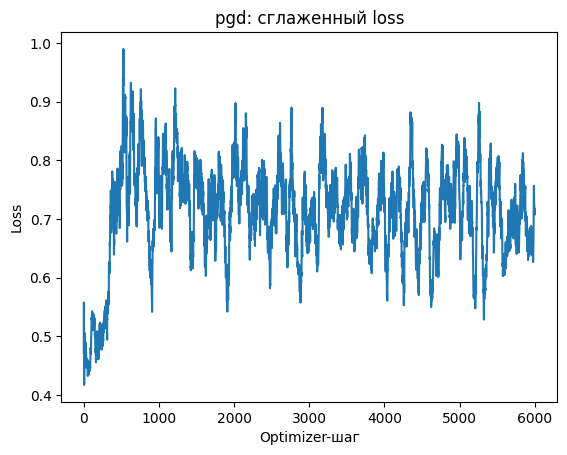

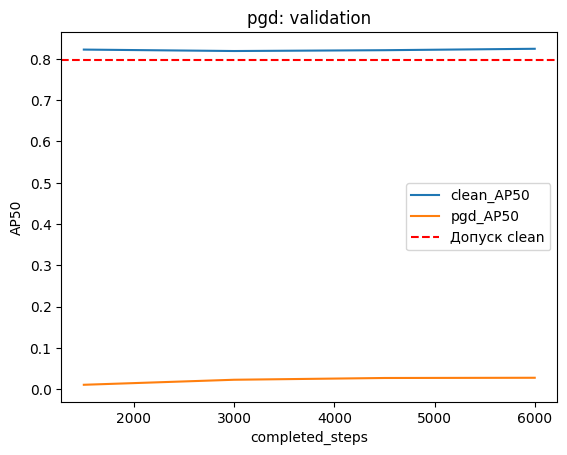

best_clean {'path': 'checkpoints/pgd/round_004.pt', 'round': 4, 'completed_steps': 6000, 'pgd_examples': 1459, 'weights_sha256': '1a88de8c5881780338b8511315a95e6b6d3ae130201fa169f85b4488dc35bbae', 'clean_AP50': 0.8246980826302874, 'pgd_AP50': 0.02741275551263422, 'clean_recall': 0.7848837209302325, 'pgd_recall': 0.13604651162790699, 'zero_gradient_fraction': 0.0}
best_robust {'path': 'checkpoints/pgd/round_004.pt', 'round': 4, 'completed_steps': 6000, 'pgd_examples': 1459, 'weights_sha256': '1a88de8c5881780338b8511315a95e6b6d3ae130201fa169f85b4488dc35bbae', 'clean_AP50': 0.8246980826302874, 'pgd_AP50': 0.02741275551263422, 'clean_recall': 0.7848837209302325, 'pgd_recall': 0.13604651162790699, 'zero_gradient_fraction': 0.0}


,Старый релиз сохранён
source_release_unchanged,True
protected_files,19
new_run,/content/drive/MyDrive/ML6/runs/blue_advft_pil...


In [ ]:
folder = branch.path('checkpoints/pgd')
history = pd.read_csv(folder/'history.csv')
display(history.groupby('mode').size().rename('Фактически применено'))
print('Разных обучающих кадров:', len(history[['video','frame_idx']].drop_duplicates()))
history.set_index('step').loss.rolling(50, min_periods=1).mean().plot(title='pgd: сглаженный loss')
plt.xlabel('Optimizer-шаг'); plt.ylabel('Loss'); plt.show()
validation_history.set_index('completed_steps')[['clean_AP50','pgd_AP50']].plot(title='pgd: validation')
plt.axhline(branch.read_baseline()['clean_AP50']-RECIPE['clean_ap50_drop'], color='red', linestyle='--', label='Допуск clean')
plt.ylabel('AP50'); plt.legend(); plt.show()
for role in ('best_clean', 'best_robust'):
    p = folder/(role+'.json')
    print(role, read_json(p) if p.exists() else 'Нет допустимого checkpoint')
display(pd.Series(branch.guard(), name='Старый релиз сохранён'))


Дообучение с PGD дало улучшение, но устойчивость остаётся низкой.
- Между первым и четвёртым раундами AP50 под PGD вырос 0,010 → 0,027, обнаружение людей — 8,6% → 13,6%.
- Под атакой только 3,9% выданных рамок правильные — ложных обнаружений очень много.
- На чистых кадрах итоговый AP50 — 0,825, обнаруживается 78,5% людей.
- Обучение завершено: 6000 шагов, выбран четвёртый раунд. Новые веса сохранены отдельно, рабочий релиз не заменён.